# E3 — Evidence-Driven Improvement Experiment

**Course:** Neural Networks for Computer Vision (HAMK)
**Project:** Urban Street Tree Classification
**Environment:** Local Laptop

---

## Experiment chain

| Experiment | Purpose | Notebook |
|---|---|---|
| E1 | ResNet-18 baseline | `Dan_E1_training_baseline_local.ipynb` |
| E2 (ResNet-50) | ResNet-18 vs ResNet-50 | `Dan_E2_training_local.ipynb` |
| E2 (ResNet-34) | ResNet-18 vs ResNet-34 | `Dan_E2_training_local_resnet34.ipynb` |
| E3 | Evidence-driven improvement | `Dan_E3_training_improvement_local.ipynb` |
| Final | Word report | Separate document |

---

## Purpose of E3

E3 is not another random training run.

E3 must answer:

> Does one specific, evidence-based change improve the model compared with the best E1/E2 baseline?

The improvement must be chosen from the error analysis of E1/E2.

### Base model selection

E3 reads the shared registry `outputs/dan/experiment_results.csv`, keeps all E1 and E2 rows (models: `resnet18`, `resnet50`, `resnet34`), and selects the row with the highest validation Macro-F1 as the base. The E3 architecture matches the selected base model — the model builder supports `resnet18`, `resnet34` and `resnet50`. E3 starts from ImageNet pretrained weights, not from the base checkpoint, so only one variable is changed: the improvement itself.

Current registry state:

| Experiment | Model | Validation Macro-F1 | Selected |
|---|---|---|---|
| E1 | resnet18 | 0.9336 | ✔ base |
| E2 | resnet34 | 0.9240 | |

Output file names follow the selected architecture, e.g. `best_resnet18_E3_class_weighted_loss.pth`.

---

## Allowed E3 improvements

Choose **one** improvement only.

### Option A — Class-weighted loss

Use this if E1/E2 error analysis shows:

- low recall for minority classes,
- low Macro-F1 compared with accuracy,
- repeated failures on small classes,
- class imbalance visible in preprocessing.

This is the default in this notebook:

```python
IMPROVEMENT = "class_weighted_loss"
```

### Option B — Stronger augmentation

Use this if E1/E2 error analysis shows:

- overfitting,
- large train/validation gap,
- failures caused by lighting, rotation, crop, or background variation,
- visually similar images that need stronger invariance.

To use this option, change the configuration cell to:

```python
IMPROVEMENT = "stronger_augmentation"
```

---

## Test-set policy

```text
TRAIN
  ↓
VALIDATION  ← choose improvement / epoch / model
  ↓
FREEZE E3 MODEL
  ↓
TEST ONCE  ← report only
```

The test set is not used to decide whether the improvement is better.
The decision is made using validation Macro-F1.

## 1. Imports, reproducibility, and device

In [12]:
import os
import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision.models import (
    resnet18,
    resnet50,
    ResNet18_Weights,
    ResNet50_Weights,
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)

SEED = 42

def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(SEED)

def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')

DEVICE = get_device()
USE_AMP = DEVICE.type == 'cuda'

print('PyTorch version:', torch.__version__)
print('Device:', DEVICE)
print('AMP enabled:', USE_AMP)

PyTorch version: 2.14.1
Device: mps
AMP enabled: False


## 2. Configuration

E3 uses the same clean dataset as E1 and E2:

```text
./data/clean_tree
```

All outputs are saved to:

```text
./outputs/dan/training
```

In [15]:
BASE_DIR = Path('.').resolve()

DATA_DIR = BASE_DIR / 'data'
CLEAN_ROOT = DATA_DIR / 'clean_tree'

TRAIN_DIR = CLEAN_ROOT / 'train'
VAL_DIR = CLEAN_ROOT / 'val'
TEST_DIR = CLEAN_ROOT / 'test'

OUTPUT_ROOT = BASE_DIR / 'outputs' / 'dan'
TRAINING_OUTPUT_DIR = OUTPUT_ROOT / 'training'
TRAINING_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BASELINE_OUTPUT_DIR = OUTPUT_ROOT / 'training_baseline'
RESULTS_PATH = OUTPUT_ROOT / 'experiment_results.csv' 

EXPECTED_NUM_CLASSES = 23
BATCH_SIZE = 32
NUM_WORKERS = 0
PIN_MEMORY = DEVICE.type == 'cuda'

EXPERIMENT_ID = 'E3'

# Choose exactly one improvement:
# - 'class_weighted_loss'
# - 'stronger_augmentation'
IMPROVEMENT = 'class_weighted_loss'

HEAD_EPOCHS = 3
FINETUNE_EPOCHS = 20
HEAD_LR = 1e-3
BACKBONE_LR = 1e-4
WEIGHT_DECAY = 1e-4
LR_FACTOR = 0.5
LR_PATIENCE = 3
EARLY_STOPPING_PATIENCE = 5

# The test set is evaluated once for the report.
# It is not used to choose the improvement.
TEST_E3_FOR_REPORT = True

assert TRAIN_DIR.exists(), f'Missing {TRAIN_DIR}. Run Dan_preprocessing_local.ipynb first.'
assert VAL_DIR.exists(), f'Missing {VAL_DIR}.'
assert TEST_DIR.exists(), f'Missing {TEST_DIR}.'

print('Experiment:', EXPERIMENT_ID)
print('Improvement:', IMPROVEMENT)
print('Train dir:', TRAIN_DIR)
print('Val dir  :', VAL_DIR)
print('Test dir :', TEST_DIR)
print('Outputs  :', TRAINING_OUTPUT_DIR)

Experiment: E3
Improvement: class_weighted_loss
Train dir: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/data/clean_tree/train
Val dir  : /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/data/clean_tree/val
Test dir : /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/data/clean_tree/test
Outputs  : /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training


## 3. Select the best baseline from E1/E2

E3 compares against the best previous experiment.

The selection rule is:

1. Read `experiment_results.csv`.
2. Keep E1 and E2 rows.
3. Choose the row with the highest validation Macro-F1.
4. Use that architecture as the E3 base model.

This keeps the experiment controlled: E3 changes only one thing compared with the best baseline.

In [16]:
BASE_ROW = None
BASE_EXPERIMENT = None
BASE_MODEL_NAME = None
BASE_VAL_F1 = np.nan

if RESULTS_PATH.exists():
    results_df_input = pd.read_csv(RESULTS_PATH)
    candidates = results_df_input[results_df_input['experiment'].isin(['E1', 'E2'])]

    if len(candidates) > 0:
        BASE_ROW = candidates.sort_values('val_f1_macro', ascending=False).iloc[0]
        BASE_EXPERIMENT = str(BASE_ROW['experiment'])
        BASE_MODEL_NAME = str(BASE_ROW['model'])
        BASE_VAL_F1 = float(BASE_ROW['val_f1_macro'])
    else:
        print('WARNING: experiment_results.csv exists, but no E1/E2 rows were found.')
else:
    print('WARNING: experiment_results.csv was not found.')

if BASE_ROW is None:
    BASE_EXPERIMENT = 'E1'
    BASE_MODEL_NAME = 'resnet18'
    BASE_VAL_F1 = np.nan
    print('Using default base model: resnet18')

if '50' in BASE_MODEL_NAME:
    ARCH_NAME = 'resnet50'
else:
    ARCH_NAME = 'resnet18'

IMPROVEMENT_TAG = IMPROVEMENT.replace(' ', '_')
MODEL_NAME = ARCH_NAME

CKPT_PATH = TRAINING_OUTPUT_DIR / f'best_{MODEL_NAME}_{EXPERIMENT_ID}_{IMPROVEMENT_TAG}.pth'
CONFIG_PATH = TRAINING_OUTPUT_DIR / f'{MODEL_NAME}_{EXPERIMENT_ID}_{IMPROVEMENT_TAG}_config.json'
TOPK_PATH = TRAINING_OUTPUT_DIR / f'{MODEL_NAME}_{EXPERIMENT_ID}_{IMPROVEMENT_TAG}_topk.json'
COMPARISON_PATH = TRAINING_OUTPUT_DIR / f'E3_improvement_comparison_{IMPROVEMENT_TAG}.csv'

print()
print('Base experiment :', BASE_EXPERIMENT)
print('Base model      :', BASE_MODEL_NAME)
print('Base val Macro-F1:', BASE_VAL_F1)
print('E3 architecture :', ARCH_NAME)
print('E3 improvement  :', IMPROVEMENT)
print()
print('Checkpoint path :', CKPT_PATH)


Base experiment : E1
Base model      : resnet18
Base val Macro-F1: 0.9336035213354524
E3 architecture : resnet18
E3 improvement  : class_weighted_loss

Checkpoint path : /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training/best_resnet18_E3_class_weighted_loss.pth


## 4. Transforms

If the improvement is `class_weighted_loss`, the training transform stays the same mild baseline transform.

If the improvement is `stronger_augmentation`, only the training transform is changed.

The validation/test transform is never changed.

In [17]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

mild_train_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert('RGB')),
    transforms.RandomResizedCrop(224, scale=(0.80, 1.00), ratio=(0.90, 1.10)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

strong_train_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert('RGB')),
    transforms.RandomResizedCrop(224, scale=(0.60, 1.00), ratio=(0.85, 1.15)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.15, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert('RGB')),
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

if IMPROVEMENT == 'class_weighted_loss':
    train_transform = mild_train_transform
elif IMPROVEMENT == 'stronger_augmentation':
    train_transform = strong_train_transform
else:
    raise ValueError('IMPROVEMENT must be either class_weighted_loss or stronger_augmentation')

print('Improvement:', IMPROVEMENT)
print('Training transform selected.')
print('Validation/test transform is fixed.')

Improvement: class_weighted_loss
Training transform selected.
Validation/test transform is fixed.


## 5. Datasets and DataLoaders

In [18]:
train_dataset = ImageFolder(root=str(TRAIN_DIR), transform=train_transform)
val_dataset = ImageFolder(root=str(VAL_DIR), transform=eval_transform)
test_dataset = ImageFolder(root=str(TEST_DIR), transform=eval_transform)

print('Dataset sizes:')
print('Train:', len(train_dataset))
print('Val  :', len(val_dataset))
print('Test :', len(test_dataset))

assert len(train_dataset.classes) == EXPECTED_NUM_CLASSES
assert train_dataset.class_to_idx == val_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

class_names = train_dataset.classes

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

print()
print('DataLoaders created.')
print('Training batches  :', len(train_loader))
print('Validation batches:', len(val_loader))
print('Test batches      :', len(test_loader))

Dataset sizes:
Train: 3850
Val  : 401
Test : 405

DataLoaders created.
Training batches  : 121
Validation batches: 13
Test batches      : 13


## 6. Loss function

If `IMPROVEMENT = "class_weighted_loss"`, class weights are computed from the training set.

The weight formula is inverse-frequency:

```text
weight_c = total_train_images / (num_classes * class_count_c)
```

The weights are then normalized so that their average is approximately 1.

This gives smaller classes more influence in the loss without changing the dataset itself.

In [19]:
class_weights = None

if IMPROVEMENT == 'class_weighted_loss':
    targets = [label for _, label in train_dataset.samples]
    class_counts = np.bincount(targets, minlength=EXPECTED_NUM_CLASSES).astype(float)
    class_counts = np.maximum(class_counts, 1.0)

    weights = class_counts.sum() / (EXPECTED_NUM_CLASSES * class_counts)
    weights = weights / weights.sum() * EXPECTED_NUM_CLASSES

    class_weights = torch.tensor(weights, dtype=torch.float32).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    weight_df = pd.DataFrame({
        'class': class_names,
        'train_count': class_counts.astype(int),
        'weight': weights,
    }).sort_values('weight', ascending=False)

    print('Class-weighted CrossEntropyLoss selected.')
    print()
    display(weight_df)
else:
    criterion = nn.CrossEntropyLoss()
    print('Standard CrossEntropyLoss selected.')

print()
print('Loss:', criterion)

Class-weighted CrossEntropyLoss selected.



,class,train_count,weight
8,Lagerstroemia indica,65,2.348478
17,Prunus cerasifera f. atropurpurea,99,1.541930
5,Flowering cherry,106,1.440104
15,Photinia serratifolia,120,1.272092
1,Cedrus deodara,125,1.221208
18,Salix babylonica,136,1.122434
21,Triadica sebifera,154,0.991241
13,Michelia chapensis,154,0.991241
20,Styphnolobium japonicum,157,0.972300
0,Acer palmatum,162,0.942290



Loss: CrossEntropyLoss()


## 7. Model

The model architecture is taken from the best E1/E2 baseline.

The model starts from ImageNet pretrained weights, not from the E2 checkpoint.

This keeps the E3 comparison cleaner because only the selected improvement is changed.

In [20]:
def build_model(arch: str, num_classes: int, device: torch.device) -> nn.Module:
    if arch == 'resnet18':
        weights = ResNet18_Weights.IMAGENET1K_V1
        model = resnet18(weights=weights)
    elif arch == 'resnet50':
        weights = ResNet50_Weights.IMAGENET1K_V1
        model = resnet50(weights=weights)
    else:
        raise ValueError(f'Unsupported architecture: {arch}')

    for param in model.parameters():
        param.requires_grad = False

    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(p=0.2),
        nn.Linear(in_features, num_classes),
    )

    return model.to(device)

model = build_model(ARCH_NAME, EXPECTED_NUM_CLASSES, DEVICE)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())

print('Architecture        :', ARCH_NAME)
print(f'Total parameters    : {total:,}')
print(f'Trainable parameters: {trainable:,}  (head only)')

Architecture        : resnet18
Total parameters    : 11,188,311
Trainable parameters: 11,799  (head only)


## 8. Optimizer and mixed precision

In [21]:
if USE_AMP:
    try:
        scaler = torch.amp.GradScaler('cuda')
    except TypeError:
        scaler = torch.cuda.amp.GradScaler()
else:
    try:
        scaler = torch.amp.GradScaler('cpu', enabled=False)
    except TypeError:
        scaler = torch.cuda.amp.GradScaler(enabled=False)

def make_optimizer(model, backbone_lr, head_lr):
    head_params = list(model.fc.parameters())
    backbone_params = [
        p for n, p in model.named_parameters()
        if not n.startswith('fc') and p.requires_grad
    ]

    groups = []
    if backbone_params:
        groups.append({'params': backbone_params, 'lr': backbone_lr})
    groups.append({'params': head_params, 'lr': head_lr})

    return optim.AdamW(groups, weight_decay=WEIGHT_DECAY)

print('Optimizer: AdamW')
print('AMP      :', USE_AMP)

Optimizer: AdamW
AMP      : False


## 9. Metrics

In [22]:
def calculate_metrics(labels, predictions):
    return {
        'accuracy': accuracy_score(labels, predictions),
        'precision_macro': precision_score(labels, predictions, average='macro', zero_division=0),
        'recall_macro': recall_score(labels, predictions, average='macro', zero_division=0),
        'f1_macro': f1_score(labels, predictions, average='macro', zero_division=0),
        'balanced_accuracy': balanced_accuracy_score(labels, predictions),
        'f1_weighted': f1_score(labels, predictions, average='weighted', zero_division=0),
    }

print('Metric functions ready.')

Metric functions ready.


## 10. Training and evaluation functions

In [23]:
def set_backbone_batchnorm_eval(model):
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

def train_one_epoch(model, loader, criterion, optimizer, scaler, device, use_amp, head_warmup=False):
    model.train()
    if head_warmup:
        set_backbone_batchnorm_eval(model)

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        if use_amp:
            with torch.autocast(device_type='cuda'):
                outputs = model(images)
                loss = criterion(outputs, labels)
        else:
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * labels.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device, use_amp):
    model.eval()
    running_loss = 0.0
    total = 0
    all_preds = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if use_amp:
            with torch.autocast(device_type='cuda'):
                outputs = model(images)
                loss = criterion(outputs, labels)
        else:
            outputs = model(images)
            loss = criterion(outputs, labels)

        running_loss += loss.item() * labels.size(0)
        preds = outputs.argmax(dim=1)
        all_preds.append(preds.cpu())
        all_labels.append(labels.cpu())
        total += labels.size(0)

    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()

    metrics = calculate_metrics(all_labels, all_preds)
    metrics['loss'] = running_loss / total
    metrics['predictions'] = all_preds
    metrics['labels'] = all_labels

    return metrics

@torch.no_grad()
def compute_topk(model, loader, device, use_amp, k_values):
    model.eval()
    max_k = min(max(k_values), EXPECTED_NUM_CLASSES)
    top_k_correct = {k: 0 for k in k_values}
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if use_amp:
            with torch.autocast(device_type='cuda'):
                outputs = model(images)
        else:
            outputs = model(images)

        top_k_preds = outputs.topk(k=max_k, dim=1).indices
        total += labels.size(0)

        for k in k_values:
            correct = (top_k_preds[:, :k] == labels.unsqueeze(1)).any(dim=1).sum().item()
            top_k_correct[k] += correct

    return {k: top_k_correct[k] / total for k in k_values}

print('Training, evaluation, and Top-k functions ready.')

Training, evaluation, and Top-k functions ready.


## 11. Train the improved model

Training uses the same two-stage strategy as E1/E2:

1. Head warmup.
2. Full fine-tuning.

Checkpoint selection uses validation Macro-F1 only.

In [24]:
history = {
    'stage': [],
    'epoch': [],
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': [],
    'val_balanced_acc': [],
    'val_f1_macro': [],
    'val_precision_macro': [],
    'val_recall_macro': [],
    'val_f1_weighted': [],
    'learning_rate': [],
}

best_val_f1_macro = -1.0
best_val_acc = -1.0
best_val_loss = float('inf')
best_val_metrics = None
epochs_without_improvement = 0

def checkpoint_is_better(f1_macro, acc, loss):
    if f1_macro > best_val_f1_macro:
        return True
    if f1_macro == best_val_f1_macro and acc > best_val_acc:
        return True
    if f1_macro == best_val_f1_macro and acc == best_val_acc and loss < best_val_loss:
        return True
    return False

def save_checkpoint(model, epoch, stage, val_metrics):
    payload = {
        'model_state_dict': model.state_dict(),
        'classes': train_dataset.classes,
        'class_to_idx': train_dataset.class_to_idx,
        'epoch': epoch,
        'stage': stage,
        'experiment': EXPERIMENT_ID,
        'base_experiment': BASE_EXPERIMENT,
        'base_model': BASE_MODEL_NAME,
        'architecture': ARCH_NAME,
        'improvement': IMPROVEMENT,
        'val_loss': val_metrics['loss'],
        'val_accuracy': val_metrics['accuracy'],
        'val_precision_macro': val_metrics['precision_macro'],
        'val_recall_macro': val_metrics['recall_macro'],
        'val_f1_macro': val_metrics['f1_macro'],
        'val_balanced_accuracy': val_metrics['balanced_accuracy'],
        'val_f1_weighted': val_metrics['f1_weighted'],
        'seed': SEED,
        'batch_size': BATCH_SIZE,
        'head_lr': HEAD_LR,
        'backbone_lr': BACKBONE_LR,
        'weight_decay': WEIGHT_DECAY,
        'class_weights': class_weights.tolist() if class_weights is not None else None,
    }
    torch.save(payload, CKPT_PATH)

print('=' * 70)
print(f'STAGE 1 — HEAD WARMUP ({HEAD_EPOCHS} epochs)')
print('=' * 70)

optimizer = make_optimizer(model, backbone_lr=0.0, head_lr=HEAD_LR)

for epoch in range(1, HEAD_EPOCHS + 1):
    t0 = time.time()

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        scaler,
        DEVICE,
        USE_AMP,
        head_warmup=True,
    )

    vm = evaluate(model, val_loader, criterion, DEVICE, USE_AMP)
    lr = optimizer.param_groups[-1]['lr']

    for k, v in {
        'stage': 'head',
        'epoch': epoch,
        'train_loss': train_loss,
        'train_acc': train_acc,
        'val_loss': vm['loss'],
        'val_acc': vm['accuracy'],
        'val_balanced_acc': vm['balanced_accuracy'],
        'val_f1_macro': vm['f1_macro'],
        'val_precision_macro': vm['precision_macro'],
        'val_recall_macro': vm['recall_macro'],
        'val_f1_weighted': vm['f1_weighted'],
        'learning_rate': lr,
    }.items():
        history[k].append(v)

    if checkpoint_is_better(vm['f1_macro'], vm['accuracy'], vm['loss']):
        best_val_f1_macro = vm['f1_macro']
        best_val_acc = vm['accuracy']
        best_val_loss = vm['loss']
        best_val_metrics = vm
        save_checkpoint(model, epoch, 'head', vm)

    print(
        f'Head {epoch:02d}/{HEAD_EPOCHS} | '
        f'train loss={train_loss:.4f} acc={train_acc:.4f} | '
        f'val loss={vm["loss"]:.4f} acc={vm["accuracy"]:.4f} '
        f'P={vm["precision_macro"]:.4f} R={vm["recall_macro"]:.4f} '
        f'F1={vm["f1_macro"]:.4f} | {time.time() - t0:.1f}s'
    )

print()
print('=' * 70)
print(f'STAGE 2 — FULL FINE-TUNING (up to {FINETUNE_EPOCHS} epochs)')
print('=' * 70)

for param in model.parameters():
    param.requires_grad = True

optimizer = make_optimizer(model, backbone_lr=BACKBONE_LR, head_lr=HEAD_LR * 0.5)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=LR_FACTOR,
    patience=LR_PATIENCE,
)

epochs_without_improvement = 0

for epoch in range(1, FINETUNE_EPOCHS + 1):
    t0 = time.time()

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        scaler,
        DEVICE,
        USE_AMP,
        head_warmup=False,
    )

    vm = evaluate(model, val_loader, criterion, DEVICE, USE_AMP)
    scheduler.step(vm['loss'])
    lr = optimizer.param_groups[0]['lr']

    for k, v in {
        'stage': 'finetune',
        'epoch': epoch,
        'train_loss': train_loss,
        'train_acc': train_acc,
        'val_loss': vm['loss'],
        'val_acc': vm['accuracy'],
        'val_balanced_acc': vm['balanced_accuracy'],
        'val_f1_macro': vm['f1_macro'],
        'val_precision_macro': vm['precision_macro'],
        'val_recall_macro': vm['recall_macro'],
        'val_f1_weighted': vm['f1_weighted'],
        'learning_rate': lr,
    }.items():
        history[k].append(v)

    improved = checkpoint_is_better(vm['f1_macro'], vm['accuracy'], vm['loss'])

    if improved:
        best_val_f1_macro = vm['f1_macro']
        best_val_acc = vm['accuracy']
        best_val_loss = vm['loss']
        best_val_metrics = vm
        epochs_without_improvement = 0
        save_checkpoint(model, epoch, 'finetune', vm)
        marker = ' *'
    else:
        epochs_without_improvement += 1
        marker = '  '

    print(
        f'FT {epoch:02d}/{FINETUNE_EPOCHS}{marker} | '
        f'train loss={train_loss:.4f} acc={train_acc:.4f} | '
        f'val loss={vm["loss"]:.4f} acc={vm["accuracy"]:.4f} '
        f'P={vm["precision_macro"]:.4f} R={vm["recall_macro"]:.4f} '
        f'F1={vm["f1_macro"]:.4f} | lr={lr:.2e} | {time.time() - t0:.1f}s'
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(f'Early stopping after epoch {epoch}.')
        break

print()
print('=' * 70)
print(f'Best validation Macro-F1 : {best_val_f1_macro:.4f}')
print(f'Best validation accuracy : {best_val_acc:.4f}')
print(f'Best validation loss     : {best_val_loss:.4f}')
print(f'Checkpoint               : {CKPT_PATH}')
print('=' * 70)

STAGE 1 — HEAD WARMUP (3 epochs)
Head 01/3 | train loss=2.9320 acc=0.1436 | val loss=2.5467 acc=0.2668 P=0.3132 R=0.2970 F1=0.2333 | 93.1s
Head 02/3 | train loss=2.4537 acc=0.2953 | val loss=2.1833 acc=0.3541 P=0.4360 R=0.3880 F1=0.3470 | 88.4s
Head 03/3 | train loss=2.1944 acc=0.3740 | val loss=2.0043 acc=0.4264 P=0.4529 R=0.4454 F1=0.4131 | 88.8s

STAGE 2 — FULL FINE-TUNING (up to 20 epochs)
FT 01/20 * | train loss=1.4306 acc=0.5699 | val loss=0.8722 acc=0.7132 P=0.7373 R=0.7359 F1=0.7179 | lr=1.00e-04 | 112.1s
FT 02/20 * | train loss=0.5847 acc=0.8119 | val loss=0.6158 acc=0.8005 P=0.8157 R=0.8084 F1=0.7973 | lr=1.00e-04 | 110.9s
FT 03/20 * | train loss=0.3489 acc=0.8922 | val loss=0.5417 acc=0.8229 P=0.8304 R=0.8346 F1=0.8246 | lr=1.00e-04 | 111.3s
FT 04/20 * | train loss=0.2302 acc=0.9358 | val loss=0.5039 acc=0.8279 P=0.8465 R=0.8476 F1=0.8370 | lr=1.00e-04 | 111.2s
FT 05/20   | train loss=0.1585 acc=0.9535 | val loss=0.4794 acc=0.8354 P=0.8589 R=0.8485 F1=0.8360 | lr=1.00e-04 | 

## 12. Learning curves

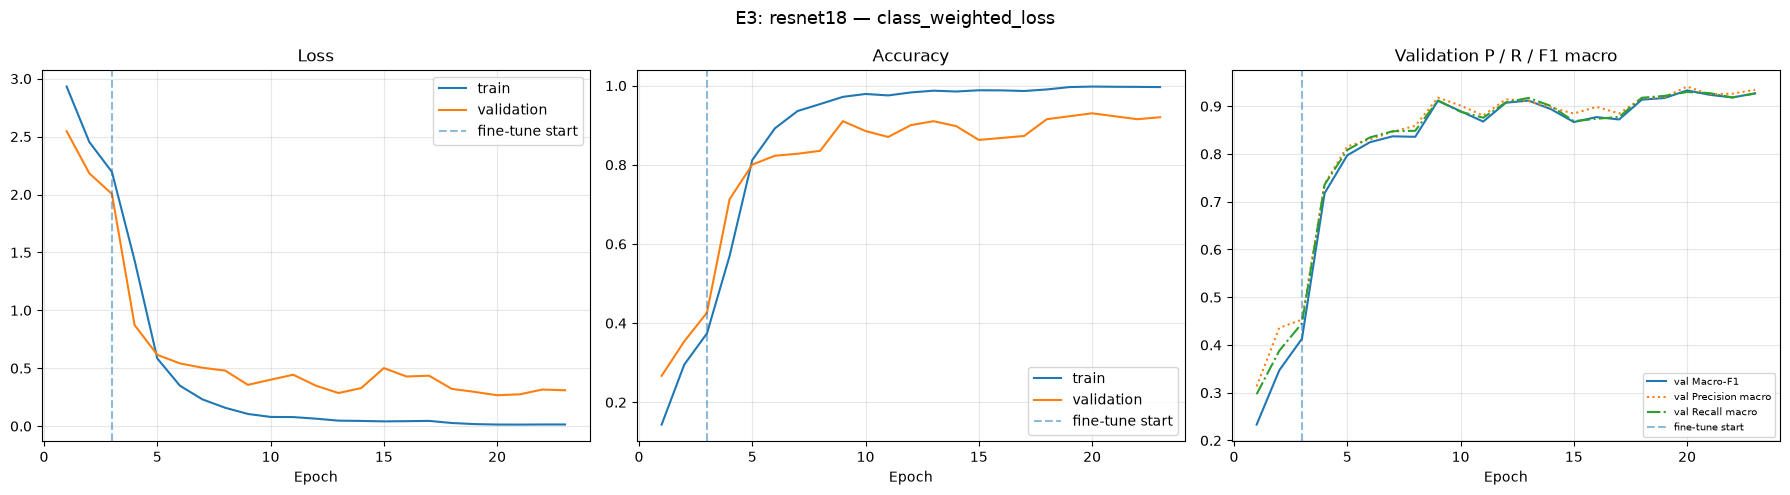

History saved: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training/resnet18_E3_class_weighted_loss_history.csv


In [25]:
history_df = pd.DataFrame(history)
history_path = TRAINING_OUTPUT_DIR / f'{MODEL_NAME}_{EXPERIMENT_ID}_{IMPROVEMENT_TAG}_history.csv'
history_df.to_csv(history_path, index=False)

epochs = np.arange(1, len(history_df) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(epochs, history_df['train_loss'], label='train')
axes[0].plot(epochs, history_df['val_loss'], label='validation')
axes[0].axvline(HEAD_EPOCHS, ls='--', alpha=0.5, label='fine-tune start')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history_df['train_acc'], label='train')
axes[1].plot(epochs, history_df['val_acc'], label='validation')
axes[1].axvline(HEAD_EPOCHS, ls='--', alpha=0.5, label='fine-tune start')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(epochs, history_df['val_f1_macro'], label='val Macro-F1')
axes[2].plot(epochs, history_df['val_precision_macro'], label='val Precision macro', ls=':')
axes[2].plot(epochs, history_df['val_recall_macro'], label='val Recall macro', ls='-.')
axes[2].axvline(HEAD_EPOCHS, ls='--', alpha=0.5, label='fine-tune start')
axes[2].set_title('Validation P / R / F1 macro')
axes[2].set_xlabel('Epoch')
axes[2].legend(fontsize=7)
axes[2].grid(alpha=0.3)

plt.suptitle(f'{EXPERIMENT_ID}: {MODEL_NAME} — {IMPROVEMENT}', fontsize=13)
plt.tight_layout()
plt.savefig(TRAINING_OUTPUT_DIR / f'{MODEL_NAME}_{EXPERIMENT_ID}_{IMPROVEMENT_TAG}_learning_curves.png', dpi=150)
plt.show()

print('History saved:', history_path)

## 13. Validation comparison against the best baseline

This is the decision table for E3.

The improvement is accepted only if validation Macro-F1 improves compared with the best E1/E2 baseline.

In [26]:
comparison_rows = []

if BASE_ROW is not None:
    comparison_rows.append({
        'experiment': BASE_EXPERIMENT,
        'model': BASE_MODEL_NAME,
        'improvement': 'baseline',
        'val_accuracy': float(BASE_ROW.get('val_accuracy', np.nan)),
        'val_precision_macro': float(BASE_ROW.get('val_precision_macro', np.nan)),
        'val_recall_macro': float(BASE_ROW.get('val_recall_macro', np.nan)),
        'val_f1_macro': float(BASE_ROW.get('val_f1_macro', np.nan)),
        'val_balanced_accuracy': float(BASE_ROW.get('val_balanced_accuracy', np.nan)),
    })

comparison_rows.append({
    'experiment': EXPERIMENT_ID,
    'model': MODEL_NAME,
    'improvement': IMPROVEMENT,
    'val_accuracy': float(best_val_metrics['accuracy']),
    'val_precision_macro': float(best_val_metrics['precision_macro']),
    'val_recall_macro': float(best_val_metrics['recall_macro']),
    'val_f1_macro': float(best_val_metrics['f1_macro']),
    'val_balanced_accuracy': float(best_val_metrics['balanced_accuracy']),
})

comparison_df = pd.DataFrame(comparison_rows)

if len(comparison_df) > 1:
    base_f1 = comparison_df['val_f1_macro'].iloc[0]
    comparison_df['delta_val_f1_macro'] = comparison_df['val_f1_macro'] - base_f1

comparison_df.to_csv(COMPARISON_PATH, index=False)

print('Validation comparison')
display(comparison_df)

improvement_confirmed = False
if BASE_ROW is not None:
    improvement_confirmed = float(best_val_metrics['f1_macro']) > float(BASE_ROW.get('val_f1_macro', np.nan))

print()
print('Improvement confirmed on validation:', improvement_confirmed)
print('Comparison table saved:', COMPARISON_PATH)

Validation comparison


,experiment,model,improvement,val_accuracy,val_precision_macro,val_recall_macro,val_f1_macro,val_balanced_accuracy,delta_val_f1_macro
0,E1,resnet18,baseline,0.932668,0.936661,0.934735,0.933604,NaN,0.000000
1,E3,resnet18,class_weighted_loss,0.930175,0.941151,0.929770,0.933111,0.92977,-0.000492



Improvement confirmed on validation: False
Comparison table saved: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training/E3_improvement_comparison_class_weighted_loss.csv


## 14. Final test evaluation

The best E3 checkpoint is loaded and evaluated once on the test set.

This test result is for reporting only.
It was not used to choose the improvement.

In [31]:
checkpoint = torch.load(CKPT_PATH, map_location=DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])

print(f'Loaded best checkpoint ({EXPERIMENT_ID})')
print('Stage       :', checkpoint['stage'])
print('Epoch       :', checkpoint['epoch'])
print('Improvement :', checkpoint['improvement'])
print('Val F1 macro:', f"{checkpoint['val_f1_macro']:.4f}")
print('Val accuracy:', f"{checkpoint['val_accuracy']:.4f}")

if TEST_E3_FOR_REPORT:
    test_metrics = evaluate(model, test_loader, criterion, DEVICE, USE_AMP)
    test_preds = test_metrics['predictions']
    test_labels = test_metrics['labels']

    print()
    print('=' * 60)
    print(f' {EXPERIMENT_ID} FINAL TEST RESULTS — {MODEL_NAME} — {IMPROVEMENT}')
    print('=' * 60)
    print(f"  Test loss              : {test_metrics['loss']:.4f}")
    print(f"  Test Accuracy          : {test_metrics['accuracy']:.4f}")
    print(f"  Test Precision macro   : {test_metrics['precision_macro']:.4f}")
    print(f"  Test Recall macro      : {test_metrics['recall_macro']:.4f}")
    print(f"  Test F1 macro          : {test_metrics['f1_macro']:.4f}")
    print(f"  Test Balanced accuracy : {test_metrics['balanced_accuracy']:.4f}")
    print(f"  Test F1 weighted       : {test_metrics['f1_weighted']:.4f}")
    print('=' * 60)

    report = classification_report(
        test_labels,
        test_preds,
        target_names=class_names,
        digits=4,
        zero_division=0,
    )

    print()
    print('Per-class classification report:')
    print(report)

    report_path = TRAINING_OUTPUT_DIR / f'{MODEL_NAME}_{EXPERIMENT_ID}_{IMPROVEMENT_TAG}_report.txt'
    with open(report_path, 'w') as f:
        f.write(report)

    print('Report saved:', report_path)
else:
    test_metrics = None
    test_preds = None
    test_labels = None
    print('Test evaluation skipped.')

Loaded best checkpoint (E3)
Stage       : finetune
Epoch       : 17
Improvement : class_weighted_loss
Val F1 macro: 0.9331
Val accuracy: 0.9302

 E3 FINAL TEST RESULTS — resnet18 — class_weighted_loss
  Test loss              : 0.6050
  Test Accuracy          : 0.8222
  Test Precision macro   : 0.8820
  Test Recall macro      : 0.8421
  Test F1 macro          : 0.8368
  Test Balanced accuracy : 0.8421
  Test F1 weighted       : 0.8229

Per-class classification report:
                                   precision    recall  f1-score   support

                    Acer palmatum     0.9474    0.9474    0.9474        19
                   Cedrus deodara     1.0000    1.0000    1.0000        13
                  Celtis sinensis     1.0000    0.4348    0.6061        23
 Cinnamomum camphora (Linn) Presl     0.9444    0.8095    0.8718        21
            Elaeocarpus decipiens     0.8636    0.9500    0.9048        20
                 Flowering cherry     1.0000    0.6154    0.7619        13
 

## 15. Top-k classification

E3 — resnet18 — class_weighted_loss — Top-k Test Accuracy
----------------------------------------
  Top- 1: 0.8222
  Top- 2: 0.9062
  Top- 3: 0.9358
  Top- 4: 0.9481
  Top- 5: 0.9556
  Top- 6: 0.9654
  Top- 7: 0.9679
  Top- 8: 0.9679
  Top- 9: 0.9728
  Top-10: 0.9778

Saved Top-k results: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training/resnet18_E3_class_weighted_loss_topk.json


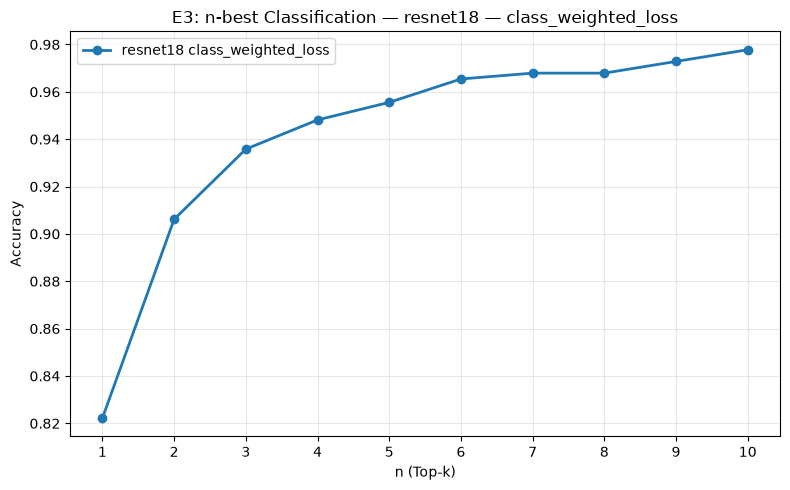

In [28]:
k_values = list(range(1, 11))
topk_acc = compute_topk(
    model=model,
    loader=test_loader,
    device=DEVICE,
    use_amp=USE_AMP,
    k_values=k_values,
)

print(f'{EXPERIMENT_ID} — {MODEL_NAME} — {IMPROVEMENT} — Top-k Test Accuracy')
print('-' * 40)
for k in k_values:
    print(f'  Top-{k:2d}: {topk_acc[k]:.4f}')

topk_payload = {
    'experiment': EXPERIMENT_ID,
    'base_experiment': BASE_EXPERIMENT,
    'model': MODEL_NAME,
    'improvement': IMPROVEMENT,
    'k_values': k_values,
    'top_k_accuracy': {str(k): topk_acc[k] for k in k_values},
}

with open(TOPK_PATH, 'w') as f:
    json.dump(topk_payload, f, indent=2)

print()
print('Saved Top-k results:', TOPK_PATH)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(k_values, [topk_acc[k] for k in k_values], marker='o', linewidth=2, label=f'{MODEL_NAME} {IMPROVEMENT}')
ax.set_xticks(k_values)
ax.set_xlabel('n (Top-k)')
ax.set_ylabel('Accuracy')
ax.set_title(f'{EXPERIMENT_ID}: n-best Classification — {MODEL_NAME} — {IMPROVEMENT}')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(TRAINING_OUTPUT_DIR / f'{MODEL_NAME}_{EXPERIMENT_ID}_{IMPROVEMENT_TAG}_topk.png', dpi=150)
plt.show()

## 16. Confusion matrix and per-class metrics

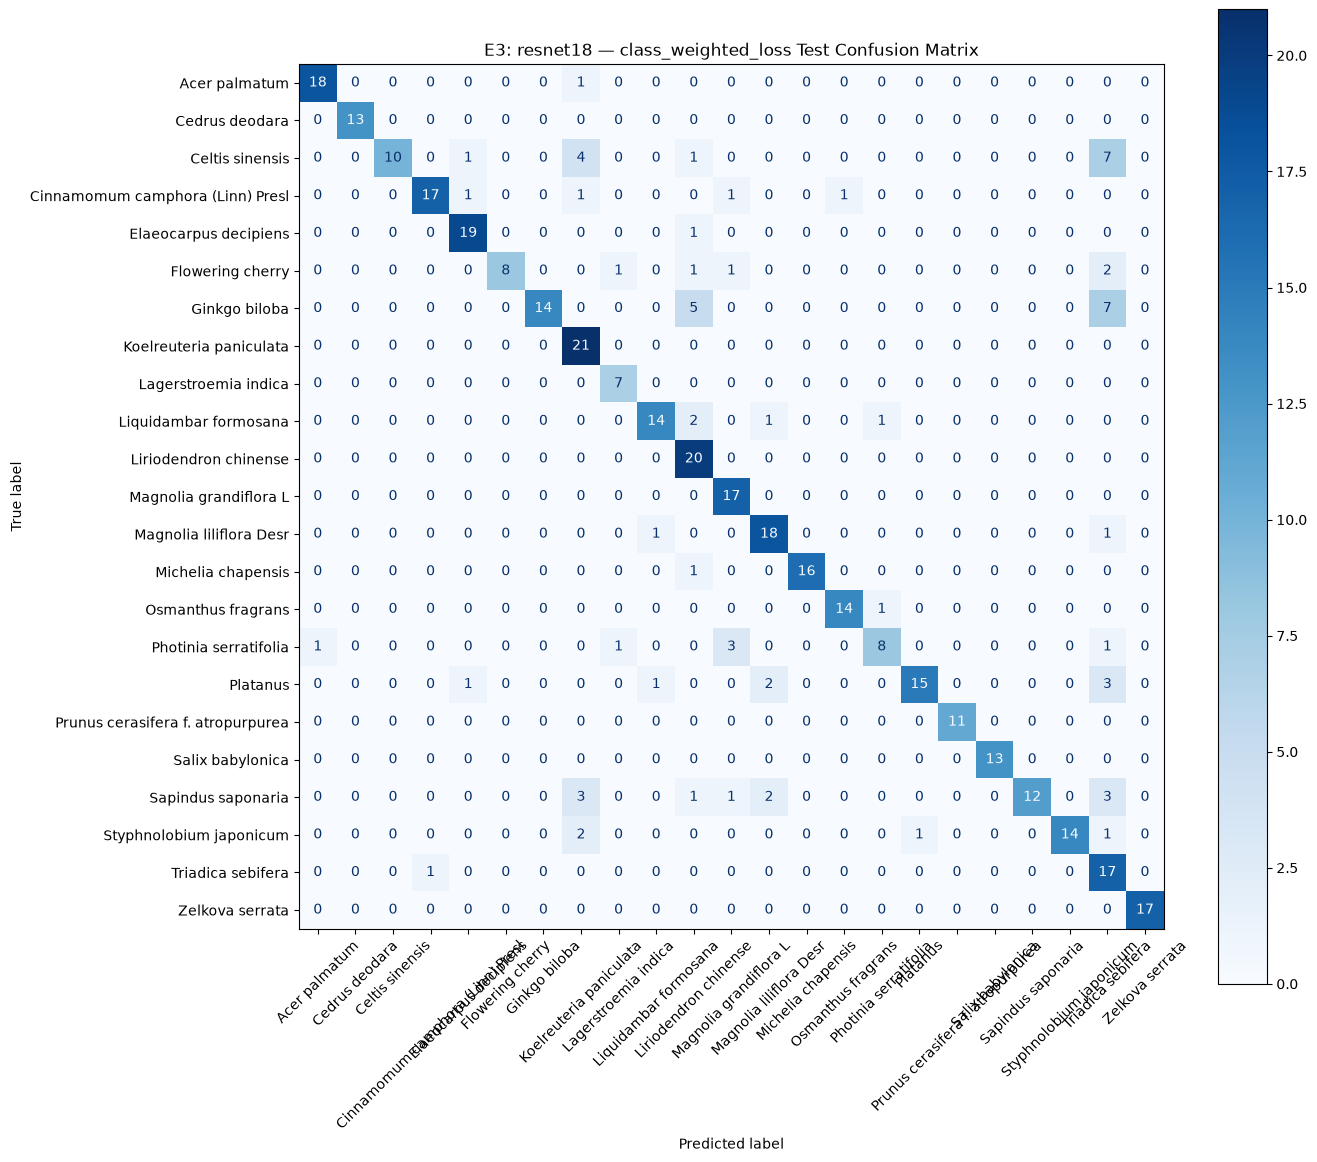

Confusion matrix saved: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training/resnet18_E3_class_weighted_loss_confusion_matrix.csv

E3: resnet18 — class_weighted_loss — Per-class metrics sorted by F1


,precision,recall,f1-score,support
Triadica sebifera,0.404762,0.944444,0.566667,18.0
Celtis sinensis,1.000000,0.434783,0.606061,23.0
Photinia serratifolia,0.800000,0.571429,0.666667,14.0
Ginkgo biloba,1.000000,0.538462,0.700000,26.0
Sapindus saponaria,1.000000,0.545455,0.705882,22.0
Flowering cherry,1.000000,0.615385,0.761905,13.0
Liriodendron chinense,0.625000,1.000000,0.769231,20.0
Platanus,0.937500,0.681818,0.789474,22.0
Koelreuteria paniculata,0.656250,1.000000,0.792453,21.0
Liquidambar formosana,0.875000,0.777778,0.823529,18.0


Per-class metrics saved: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training/resnet18_E3_class_weighted_loss_per_class.csv


In [29]:
cm = confusion_matrix(test_labels, test_preds)

fig, ax = plt.subplots(figsize=(14, 12))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, values_format='d', cmap='Blues')
plt.title(f'{EXPERIMENT_ID}: {MODEL_NAME} — {IMPROVEMENT} Test Confusion Matrix')
plt.tight_layout()
plt.savefig(TRAINING_OUTPUT_DIR / f'{MODEL_NAME}_{EXPERIMENT_ID}_{IMPROVEMENT_TAG}_confusion_matrix.png', dpi=150)
plt.show()

cm_path = TRAINING_OUTPUT_DIR / f'{MODEL_NAME}_{EXPERIMENT_ID}_{IMPROVEMENT_TAG}_confusion_matrix.csv'
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(cm_path)
print('Confusion matrix saved:', cm_path)

report_dict = classification_report(
    test_labels,
    test_preds,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

per_class_df = pd.DataFrame(report_dict).T
per_class_df = per_class_df.loc[
    [name for name in class_names if name in per_class_df.index],
    ['precision', 'recall', 'f1-score', 'support'],
]
per_class_df = per_class_df.sort_values('f1-score')

print()
print(f'{EXPERIMENT_ID}: {MODEL_NAME} — {IMPROVEMENT} — Per-class metrics sorted by F1')
display(per_class_df)

per_class_path = TRAINING_OUTPUT_DIR / f'{MODEL_NAME}_{EXPERIMENT_ID}_{IMPROVEMENT_TAG}_per_class.csv'
per_class_df.to_csv(per_class_path)
print('Per-class metrics saved:', per_class_path)

## 17. Error analysis for the Word report

This section answers:

- Did the improvement fix the original weakness?
- Which classes still fail?
- Are the remaining errors visual, label-related, or imbalance-related?
- What would be the next improvement if more time were available?

Misclassified: 72 of 405 test images

Top 10 confusion pairs true → predicted:
(Celtis sinensis, Triadica sebifera)               7
(Ginkgo biloba, Triadica sebifera)                 7
(Ginkgo biloba, Liriodendron chinense)             5
(Celtis sinensis, Koelreuteria paniculata)         4
(Photinia serratifolia, Magnolia grandiflora L)    3
(Platanus, Triadica sebifera)                      3
(Sapindus saponaria, Koelreuteria paniculata)      3
(Sapindus saponaria, Triadica sebifera)            3
(Flowering cherry, Triadica sebifera)              2
(Liquidambar formosana, Liriodendron chinense)     2


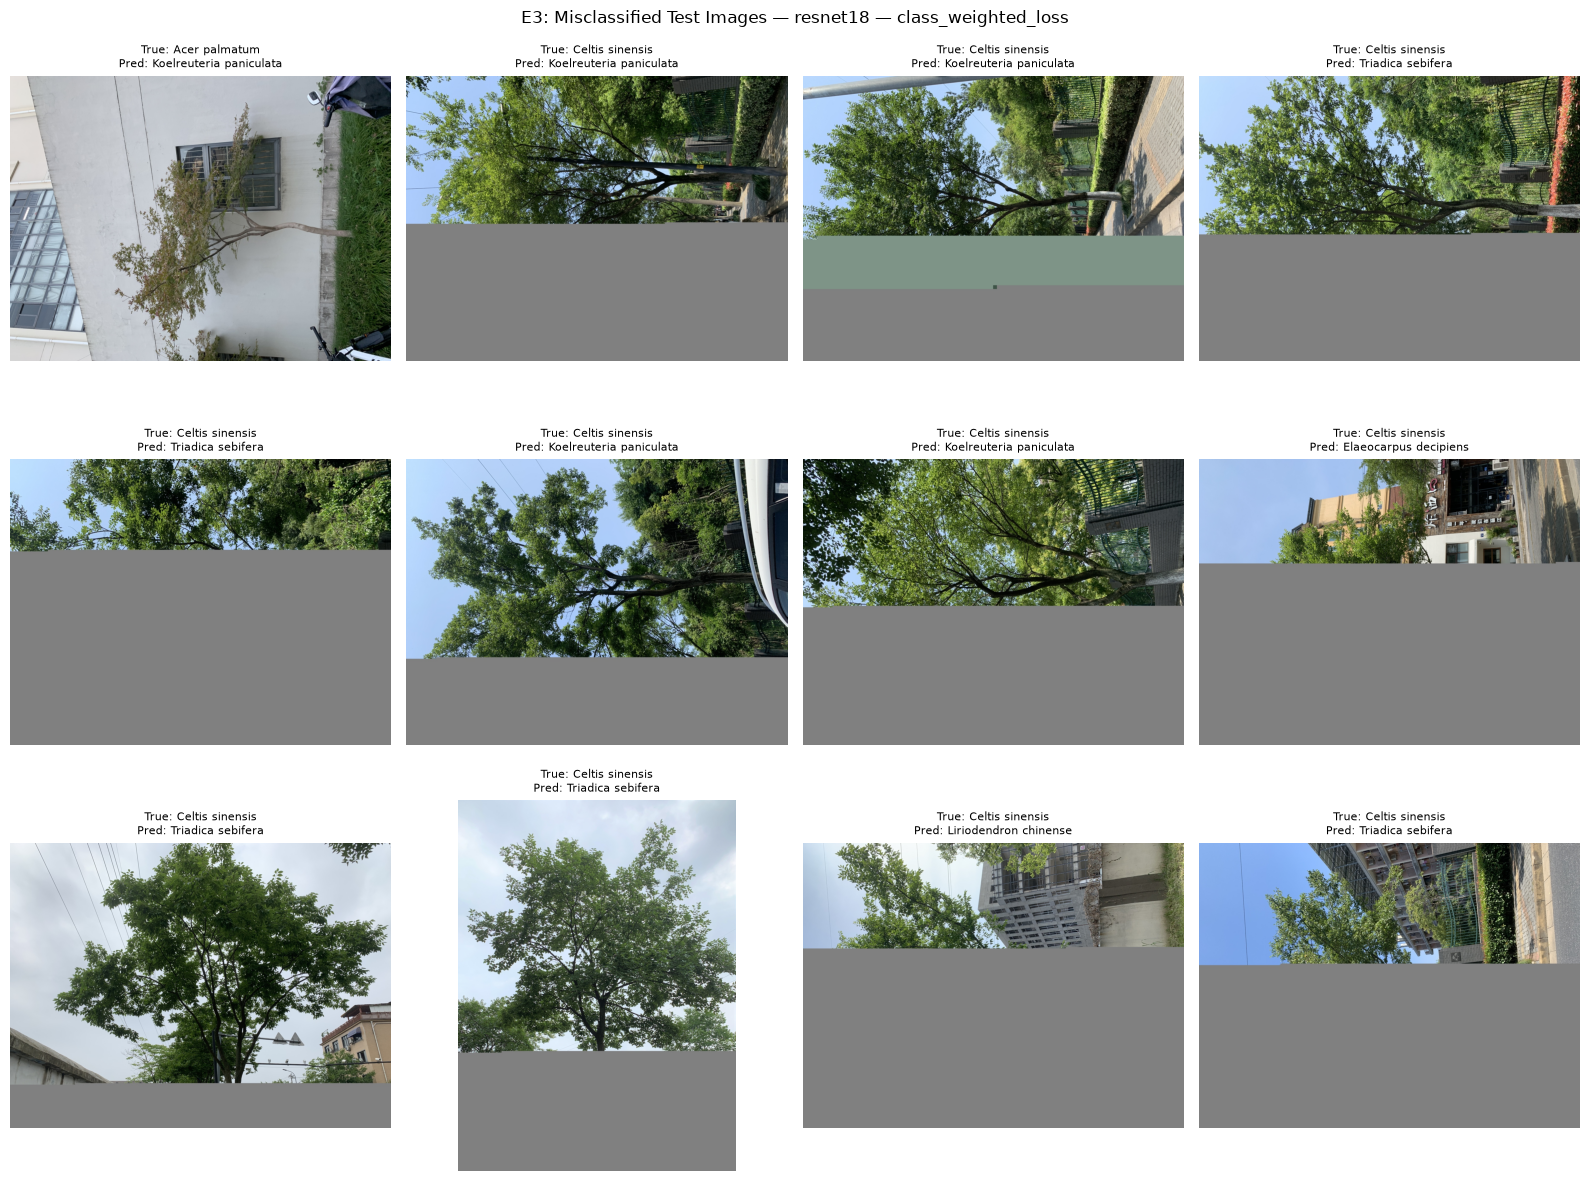

In [30]:
misclassified_idx = np.where(test_preds != test_labels)[0]
print(f'Misclassified: {len(misclassified_idx)} of {len(test_labels)} test images')

confusion_pairs = []
for idx in misclassified_idx:
    true_cls = class_names[test_labels[idx]]
    pred_cls = class_names[test_preds[idx]]
    confusion_pairs.append((true_cls, pred_cls))

if confusion_pairs:
    pair_counts = pd.Series(confusion_pairs).value_counts().head(10)
    print()
    print('Top 10 confusion pairs true → predicted:')
    print(pair_counts.to_string())

n_show = min(12, len(misclassified_idx))

if n_show > 0:
    n_cols = 4
    n_rows = int(np.ceil(n_show / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis('off')

    for ax, idx in zip(axes, misclassified_idx[:n_show]):
        path, true_label = test_dataset.samples[idx]
        pred_label = int(test_preds[idx])

        try:
            with Image.open(path) as img:
                ax.imshow(img.convert('RGB'))
            ax.set_title(
                f'True: {class_names[true_label]}\nPred: {class_names[pred_label]}',
                fontsize=8,
            )
        except Exception:
            ax.set_title('Could not load')

        ax.axis('off')

    plt.suptitle(f'{EXPERIMENT_ID}: Misclassified Test Images — {MODEL_NAME} — {IMPROVEMENT}')
    plt.tight_layout()
    plt.savefig(TRAINING_OUTPUT_DIR / f'{MODEL_NAME}_{EXPERIMENT_ID}_{IMPROVEMENT_TAG}_errors.png', dpi=150)
    plt.show()
else:
    print('No misclassified test images.')

## 18. Save configuration and update experiment registry

In [32]:
config = {
    'experiment_id': EXPERIMENT_ID,
    'base_experiment': BASE_EXPERIMENT,
    'base_model': BASE_MODEL_NAME,
    'architecture': ARCH_NAME,
    'improvement': IMPROVEMENT,
    'pretrained': 'ImageNet',
    'num_classes': EXPECTED_NUM_CLASSES,
    'train_images': len(train_dataset),
    'val_images': len(val_dataset),
    'test_images': len(test_dataset),
    'seed': SEED,
    'batch_size': BATCH_SIZE,
    'head_epochs': HEAD_EPOCHS,
    'finetune_epochs': FINETUNE_EPOCHS,
    'head_lr': HEAD_LR,
    'backbone_lr': BACKBONE_LR,
    'weight_decay': WEIGHT_DECAY,
    'optimizer': 'AdamW',
    'scheduler': 'ReduceLROnPlateau',
    'primary_metric': 'val_f1_macro',
    'use_amp': USE_AMP,
    'class_weights': class_weights.tolist() if class_weights is not None else None,
    'val_accuracy': float(best_val_metrics['accuracy']),
    'val_precision_macro': float(best_val_metrics['precision_macro']),
    'val_recall_macro': float(best_val_metrics['recall_macro']),
    'val_f1_macro': float(best_val_metrics['f1_macro']),
    'val_balanced_accuracy': float(best_val_metrics['balanced_accuracy']),
    'val_f1_weighted': float(best_val_metrics['f1_weighted']),
}

if test_metrics is not None:
    config.update({
        'test_accuracy': float(test_metrics['accuracy']),
        'test_precision_macro': float(test_metrics['precision_macro']),
        'test_recall_macro': float(test_metrics['recall_macro']),
        'test_f1_macro': float(test_metrics['f1_macro']),
        'test_balanced_accuracy': float(test_metrics['balanced_accuracy']),
        'test_f1_weighted': float(test_metrics['f1_weighted']),
        'test_top5': float(topk_acc[5]),
    })

with open(CONFIG_PATH, 'w') as f:
    json.dump(config, f, indent=2)

print('Config saved:', CONFIG_PATH)

result_row = {
    'experiment': EXPERIMENT_ID,
    'model': MODEL_NAME,
    'improvement': IMPROVEMENT,
    'base_experiment': BASE_EXPERIMENT,
    'val_f1_macro': float(best_val_metrics['f1_macro']),
    'val_accuracy': float(best_val_metrics['accuracy']),
    'val_precision_macro': float(best_val_metrics['precision_macro']),
    'val_recall_macro': float(best_val_metrics['recall_macro']),
    'val_balanced_accuracy': float(best_val_metrics['balanced_accuracy']),
}

if test_metrics is not None:
    result_row.update({
        'test_accuracy': float(test_metrics['accuracy']),
        'test_precision_macro': float(test_metrics['precision_macro']),
        'test_recall_macro': float(test_metrics['recall_macro']),
        'test_f1_macro': float(test_metrics['f1_macro']),
        'test_balanced_accuracy': float(test_metrics['balanced_accuracy']),
        'test_top5': float(topk_acc[5]),
    })

if RESULTS_PATH.exists():
    results_df = pd.read_csv(RESULTS_PATH)
    if 'experiment' in results_df.columns:
        results_df = results_df[results_df['experiment'] != EXPERIMENT_ID]
else:
    results_df = pd.DataFrame()

results_df = pd.concat([results_df, pd.DataFrame([result_row])], ignore_index=True)
results_df.to_csv(RESULTS_PATH, index=False)

print()
print('Experiment registry updated:', RESULTS_PATH)
display(results_df)

Config saved: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training/resnet18_E3_class_weighted_loss_config.json

Experiment registry updated: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/experiment_results.csv


,experiment,model,augmentation,loss,optimizer,val_f1_macro,val_accuracy,val_precision_macro,val_recall_macro,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_balanced_accuracy,improvement,base_experiment,val_balanced_accuracy,test_top5
0,E1,resnet18,baseline_mild,CrossEntropyLoss,AdamW,0.933604,0.932668,0.936661,0.934735,0.832099,0.881950,0.848400,0.844915,0.848400,NaN,NaN,NaN,NaN
1,E3,resnet18,NaN,NaN,NaN,0.933111,0.930175,0.941151,0.929770,0.822222,0.882035,0.842119,0.836784,0.842119,class_weighted_loss,E1,0.92977,0.955556
